In [ ]:
import os, glob, importlib.util

NAMA_FILE = 'dataset_penyakit.csv'
FOLDER_DRIVE = '/content/drive/MyDrive/Data Mining'

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    BASE_DIR = FOLDER_DRIVE
    if not os.path.exists(os.path.join(BASE_DIR, NAMA_FILE)):          # cari otomatis di seluruh Drive
        ketemu = glob.glob(f'/content/drive/MyDrive/Data Mining/{NAMA_FILE}', recursive=True)
        if ketemu: BASE_DIR = os.path.dirname(ketemu[0])
        else: raise FileNotFoundError(f'{NAMA_FILE} tidak ditemukan di Drive. Pastikan file sudah diunggah ke Google Drive.')
else:
    BASE_DIR = '.'
print('Folder kerja :', BASE_DIR)
print('File dataset :', os.path.join(BASE_DIR, NAMA_FILE), '->', 'ADA' if os.path.exists(os.path.join(BASE_DIR, NAMA_FILE)) else 'TIDAK ADA')

# Pasang gradio bila belum tersedia (dipakai di bagian akhir notebook)
if importlib.util.find_spec('gradio') is None:
    get_ipython().run_line_magic('pip', 'install -q gradio')

Mounted at /content/drive
Folder kerja : /content/drive/MyDrive/Data Mining
File dataset : /content/drive/MyDrive/Data Mining/dataset_penyakit.csv -> ADA


In [ ]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=0.95)
RNG = np.random.default_rng(42)
ORD = ['Normal', 'Diabetes', 'Hipertensi', 'Jantung']
PAL = {'Normal':'#2a9d8f','Diabetes':'#e9c46a','Hipertensi':'#f4a261','Jantung':'#e76f51'}

DATA_PATH = os.path.join(BASE_DIR, NAMA_FILE)
df = pd.read_csv(DATA_PATH)
NUM = ['Umur','Tekanan_Darah','Kadar_Gula','Detak_Jantung','BMI']
CAT = ['Jenis_Kelamin','Riwayat_Keluarga','Gaya_Hidup']
TARGET = 'Penyakit'
df.head()

,Umur,Tekanan_Darah,Kadar_Gula,Detak_Jantung,BMI,Jenis_Kelamin,Riwayat_Keluarga,Gaya_Hidup,Penyakit
0,25,120,85,72,22,Laki-laki,Tidak,Sehat,Normal
1,45,140,150,80,28,Perempuan,Ya,Tidak_Sehat,Diabetes
2,50,150,160,85,30,Laki-laki,Ya,Tidak_Sehat,Diabetes
3,60,170,110,90,32,Perempuan,Ya,Sedang,Hipertensi
4,55,165,100,88,31,Laki-laki,Tidak,Tidak_Sehat,Hipertensi


## 1. Ringkasan Dataset

In [ ]:
print('Ukuran dataset (baris, kolom):', df.shape)
print()
df.info()
display(df[NUM].describe().T.round(2))
display(df[TARGET].value_counts().to_frame('jumlah').assign(persen=lambda x: (x.jumlah/len(df)*100).round(1)))

Ukuran dataset (baris, kolom): (101, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Umur              101 non-null    int64 
 1   Tekanan_Darah     101 non-null    int64 
 2   Kadar_Gula        101 non-null    int64 
 3   Detak_Jantung     101 non-null    int64 
 4   BMI               101 non-null    int64 
 5   Jenis_Kelamin     101 non-null    object
 6   Riwayat_Keluarga  101 non-null    object
 7   Gaya_Hidup        101 non-null    object
 8   Penyakit          101 non-null    object
dtypes: int64(5), object(4)
memory usage: 7.2+ KB


,count,mean,std,min,25%,50%,75%,max
Umur,101.0,47.53,13.55,21.0,37.0,48.0,58.0,72.0
Tekanan_Darah,101.0,151.39,20.01,116.0,133.0,150.0,169.0,185.0
Kadar_Gula,101.0,122.30,25.86,81.0,98.0,120.0,145.0,165.0
Detak_Jantung,101.0,83.71,7.41,69.0,78.0,84.0,89.0,99.0
BMI,101.0,29.23,4.45,20.0,26.0,30.0,33.0,38.0


,jumlah,persen
Penyakit,,
Normal,30,29.7
Diabetes,24,23.8
Hipertensi,24,23.8
Jantung,23,22.8


**Kemungkinan variabel target:** `Penyakit` (klasifikasi 4 kelas: Normal, Diabetes, Hipertensi, Jantung) sebagai target utama;
`Sakit vs Normal` (biner) sebagai turunan; atau `Kadar_Gula` / `Tekanan_Darah` sebagai target regresi.

## 2. Rencana Eksplorasi
A) audit kualitas → B) univariat → C) bivariat terhadap target → D) multivariat (korelasi, VIF, PCA) → E) rekayasa fitur → F) uji hipotesis → G) pemodelan baseline dan penyimpanan model.

## 3. Audit Kualitas Data

In [ ]:
print('Nilai hilang total :', int(df.isna().sum().sum()))
print('Baris duplikat      :', int(df.duplicated().sum()))
print('Spasi berlebih      :', int(sum(df[c].astype(str).str.strip().ne(df[c].astype(str)).sum() for c in CAT+[TARGET])))

rows = []
for c in NUM:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3-q1
    n_out = int(((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum())
    rows.append((c, df[c].min(), df[c].max(), n_out, round(df[c].skew(), 2)))
display(pd.DataFrame(rows, columns=['fitur','min','maks','pencilan_IQR','skewness']))

# pengamatan ekstrem DI DALAM kelas (|z| > 3)
for c in NUM:
    for k, g in df.groupby(TARGET):
        z = (g[c]-g[c].mean())/g[c].std()
        for i in g.index[z.abs() > 3]:
            print(f'|z|>3 dalam kelas -> indeks {i}: {c}={df.loc[i, c]} (kelas {k}, z={z[i]:.2f})')

Nilai hilang total : 0
Baris duplikat      : 0
Spasi berlebih      : 0


,fitur,min,maks,pencilan_IQR,skewness
0,Umur,21,72,0,-0.12
1,Tekanan_Darah,116,185,0,-0.12
2,Kadar_Gula,81,165,0,0.03
3,Detak_Jantung,69,99,0,0.02
4,BMI,20,38,0,-0.20


|z|>3 dalam kelas -> indeks 90: Tekanan_Darah=158 (kelas Jantung, z=-3.42)
|z|>3 dalam kelas -> indeks 91: Kadar_Gula=118 (kelas Normal, z=3.26)
|z|>3 dalam kelas -> indeks 89: BMI=28 (kelas Hipertensi, z=-3.03)


## 4. Analisis Data Eksploratif (EDA)

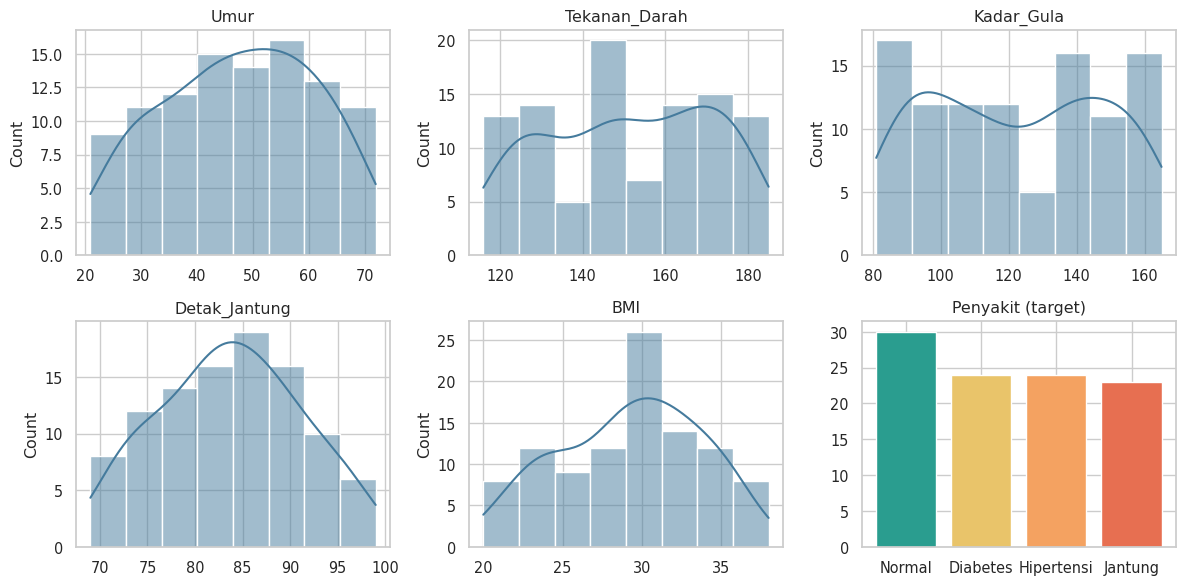

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, c in zip(ax.ravel(), NUM):
    sns.histplot(df[c], kde=True, ax=a, color='#457b9d'); a.set_title(c); a.set_xlabel('')
vc = df[TARGET].value_counts().reindex(ORD)
ax.ravel()[5].bar(vc.index, vc.values, color=[PAL[k] for k in vc.index]); ax.ravel()[5].set_title('Penyakit (target)')
plt.tight_layout(); plt.show()

Umur      Tekanan_Darah      Kadar_Gula      Detak_Jantung       \
            mean  std          mean  std       mean  std          mean  std   
Penyakit                                                                      
Normal      30.9  5.4         126.1  5.6       92.0  8.0          74.9  3.1   
Diabetes    44.7  3.3         146.8  3.6      154.2  8.9          82.2  1.7   
Hipertensi  54.7  3.4         163.6  5.1      111.9  7.0          86.9  2.1   
Jantung     64.8  4.4         176.4  5.4      139.4  6.1          93.4  3.2   

             BMI       
            mean  std  
Penyakit               
Normal      23.6  1.8  
Diabetes    28.7  1.0  
Hipertensi  31.5  1.1  
Jantung     34.8  1.6

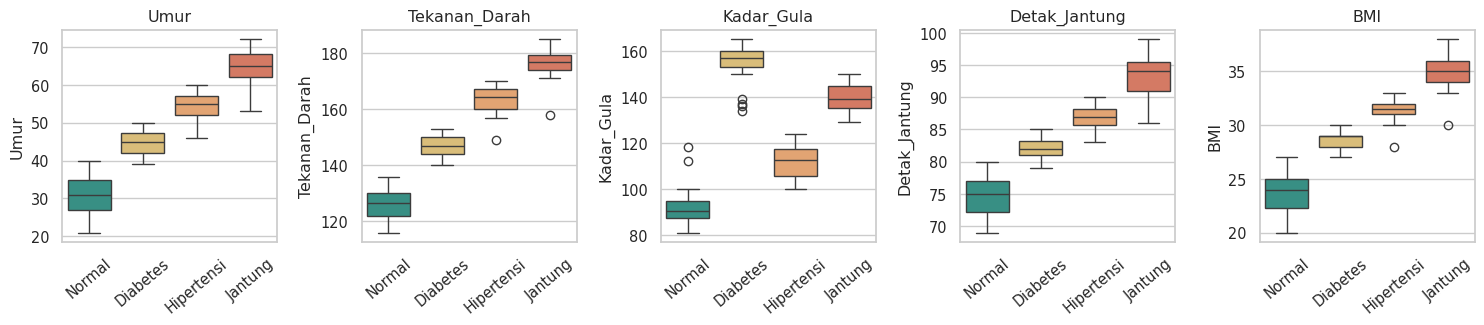

In [ ]:
g = df.groupby(TARGET)[NUM].agg(['mean','std']).round(1).reindex(ORD)
display(g)
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a, c in zip(ax, NUM):
    sns.boxplot(data=df, x=TARGET, y=c, order=ORD, palette=PAL, ax=a); a.set_title(c); a.set_xlabel(''); a.tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.show()

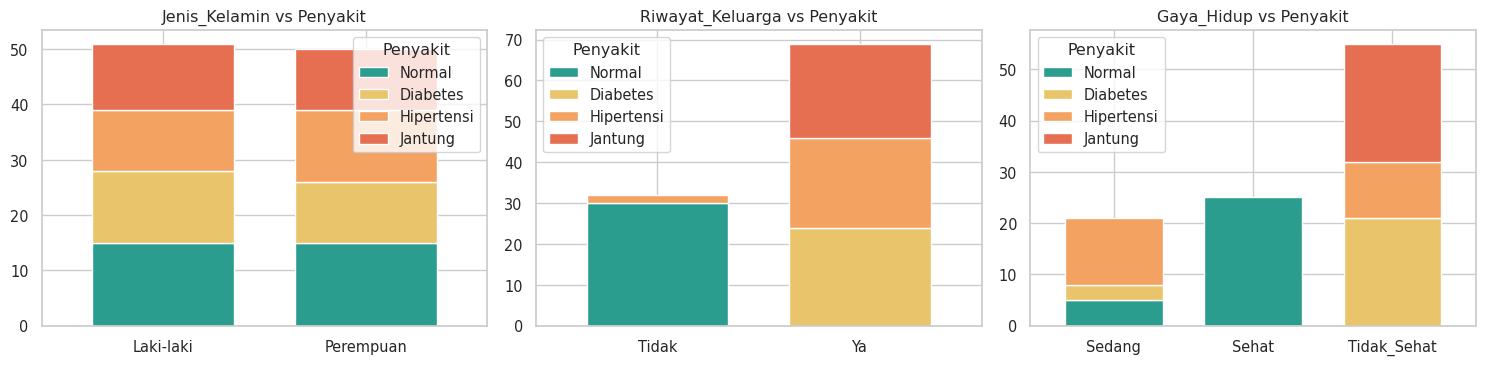

Penyakit,Normal,Diabetes,Hipertensi,Jantung
Jenis_Kelamin,,,,
Laki-laki,15,13,11,12
Perempuan,15,11,13,11


Penyakit,Normal,Diabetes,Hipertensi,Jantung
Riwayat_Keluarga,,,,
Tidak,30,0,2,0
Ya,0,24,22,23


Penyakit,Normal,Diabetes,Hipertensi,Jantung
Gaya_Hidup,,,,
Sedang,5,3,13,0
Sehat,25,0,0,0
Tidak_Sehat,0,21,11,23


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, CAT):
    pd.crosstab(df[c], df[TARGET])[ORD].plot(kind='bar', stacked=True, ax=a, color=[PAL[k] for k in ORD], width=.7)
    a.set_title(f'{c} vs Penyakit'); a.set_xlabel(''); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
for c in CAT: display(pd.crosstab(df[c], df[TARGET])[ORD])

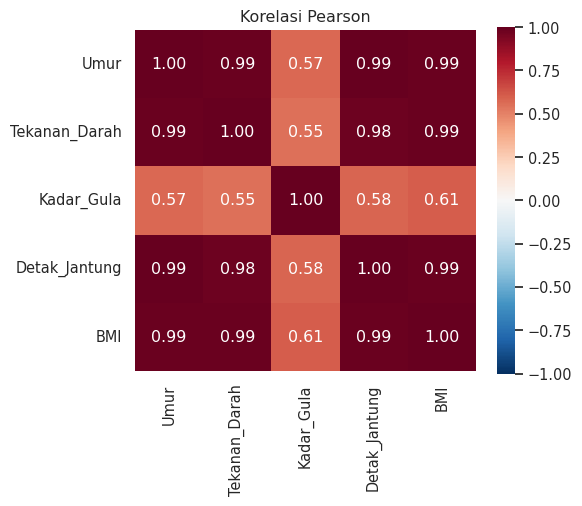

,VIF
Umur,140.3
Tekanan_Darah,71.0
Kadar_Gula,1.9
Detak_Jantung,77.2
BMI,100.0


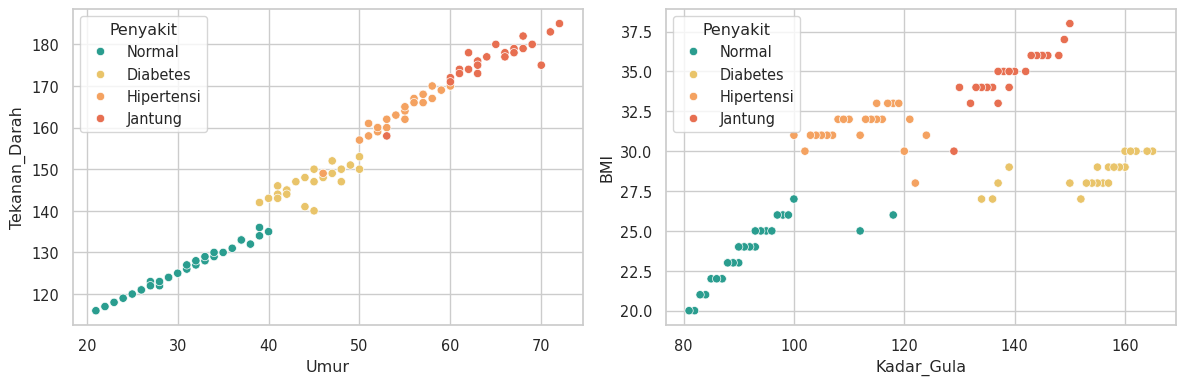

In [ ]:
# Korelasi + VIF (multikolinearitas)
plt.figure(figsize=(5.5, 4.5)); sns.heatmap(df[NUM].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True); plt.title('Korelasi Pearson'); plt.show()

def vif(X):
    out = {}
    for i, c in enumerate(X.columns):
        y = X[c].values; Z = np.c_[np.ones(len(X)), np.delete(X.values, i, axis=1)]
        b = np.linalg.lstsq(Z, y, rcond=None)[0]; r2 = 1-((y-Z@b)**2).sum()/((y-y.mean())**2).sum()
        out[c] = round(1/(1-r2), 1)
    return pd.Series(out, name='VIF')
display(vif(df[NUM]).to_frame())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x='Umur', y='Tekanan_Darah', hue=TARGET, hue_order=ORD, palette=PAL, ax=ax[0])
sns.scatterplot(data=df, x='Kadar_Gula', y='BMI', hue=TARGET, hue_order=ORD, palette=PAL, ax=ax[1])
plt.tight_layout(); plt.show()

**Temuan EDA:** (1) Umur, Tekanan_Darah, Detak_Jantung, dan BMI naik berurutan Normal < Diabetes < Hipertensi < Jantung;
(2) Kadar_Gula adalah satu-satunya fitur non-monoton (tertinggi pada Diabetes) dan independen dari blok lainnya (VIF ≈ 2);
(3) keempat fitur lain sangat kolinear (VIF 70–140); (4) Gaya_Hidup dan Riwayat_Keluarga hampir deterministik untuk Normal vs Sakit; (5) Jenis_Kelamin tidak informatif.

## 5. Pembersihan Data & Rekayasa Fitur

In [ ]:
d = df.copy()
# Pengkodean
d['Jenis_Kelamin_enc']    = (d['Jenis_Kelamin'] == 'Laki-laki').astype(int)
d['Riwayat_Keluarga_enc'] = (d['Riwayat_Keluarga'] == 'Ya').astype(int)
d['Gaya_Hidup_ord']       = d['Gaya_Hidup'].map({'Sehat':0, 'Sedang':1, 'Tidak_Sehat':2})
d['Target_4kelas']        = d[TARGET].map({k:i for i, k in enumerate(ORD)})
d['Target_biner']         = (d[TARGET] != 'Normal').astype(int)

# Pengelompokan klinis (asumsi: TD sistolik mmHg, gula puasa mg/dL, BMI kriteria Asia-Pasifik)
d['Kelompok_Umur'] = pd.cut(d['Umur'], [0,39,54,120], labels=['<40','40-54','>=55'])
d['Kategori_BMI']  = pd.cut(d['BMI'], [0,22.99,24.99,29.99,100], labels=['Normal','Berisiko','Obesitas I','Obesitas II'])
d['Kategori_TD']   = pd.cut(d['Tekanan_Darah'], [0,129,139,1000], labels=['<130','130-139','>=140'])
d['Kategori_Gula'] = pd.cut(d['Kadar_Gula'], [0,99,125,1000], labels=['<100','100-125','>=126'])

# PCA untuk blok fitur yang sangat kolinear
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
blok = ['Umur','Tekanan_Darah','Detak_Jantung','BMI']
Z = StandardScaler().fit_transform(d[blok]); pca = PCA().fit(Z)
d['PC1_Fisiologis'] = pca.transform(Z)[:, 0]
if d.loc[d[TARGET]=='Jantung', 'PC1_Fisiologis'].mean() < 0: d['PC1_Fisiologis'] *= -1
print('Varians dijelaskan PCA:', np.round(pca.explained_variance_ratio_, 4))
print('Ukuran dataset akhir  :', d.shape)
d.to_csv(os.path.join(BASE_DIR, 'dataset_penyakit_bersih.csv'), index=False)
d.head()

Varians dijelaskan PCA: [0.992  0.0044 0.0023 0.0013]
Ukuran dataset akhir  : (101, 19)


,Umur,Tekanan_Darah,Kadar_Gula,Detak_Jantung,BMI,Jenis_Kelamin,Riwayat_Keluarga,Gaya_Hidup,Penyakit,Jenis_Kelamin_enc,Riwayat_Keluarga_enc,Gaya_Hidup_ord,Target_4kelas,Target_biner,Kelompok_Umur,Kategori_BMI,Kategori_TD,Kategori_Gula,PC1_Fisiologis
0,25,120,85,72,22,Laki-laki,Tidak,Sehat,Normal,1,0,0,0,0,<40,Normal,<130,<100,-3.233882
1,45,140,150,80,28,Perempuan,Ya,Tidak_Sehat,Diabetes,0,1,2,1,1,40-54,Obesitas I,>=140,>=126,-0.769831
2,50,150,160,85,30,Laki-laki,Ya,Tidak_Sehat,Diabetes,1,1,2,1,1,40-54,Obesitas II,>=140,>=126,0.231256
3,60,170,110,90,32,Perempuan,Ya,Sedang,Hipertensi,0,1,1,2,1,>=55,Obesitas II,>=140,100-125,1.668807
4,55,165,100,88,31,Laki-laki,Tidak,Tidak_Sehat,Hipertensi,1,0,2,2,1,>=55,Obesitas II,>=140,100-125,1.109264


In [ ]:
# Simulasi imputasi (data asli tidak punya nilai hilang): sembunyikan 5% sel secara acak
from sklearn.impute import KNNImputer, SimpleImputer
Xz = StandardScaler().fit_transform(df[NUM].astype(float)); mask = RNG.random(Xz.shape) < 0.05
Xm = Xz.copy(); Xm[mask] = np.nan
for nama, imp in [('Median', SimpleImputer(strategy='median')), ('KNN (k=5)', KNNImputer(n_neighbors=5))]:
    rmse = np.sqrt((((imp.fit_transform(Xm)-Xz)[mask])**2).mean())
    print(f'{nama:10s} RMSE (z-skor) = {rmse:.3f}   [{mask.sum()} sel disembunyikan]')

Median     RMSE (z-skor) = 0.867   [22 sel disembunyikan]
KNN (k=5)  RMSE (z-skor) = 0.486   [22 sel disembunyikan]


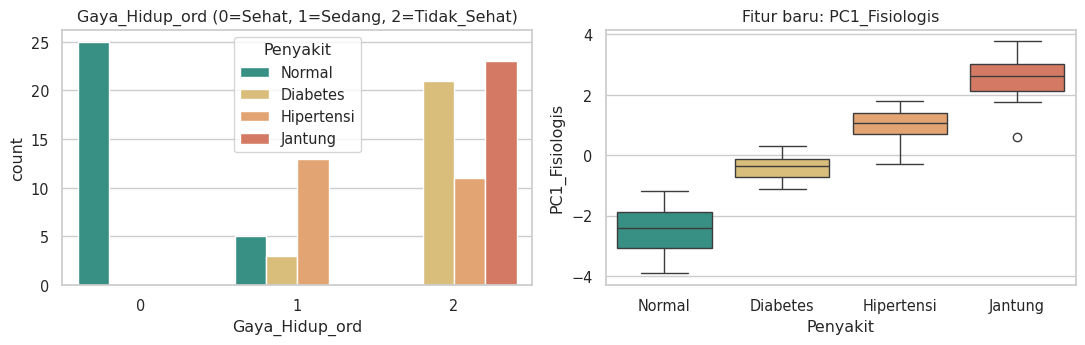

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(data=d, x='Gaya_Hidup_ord', hue=TARGET, hue_order=ORD, palette=PAL, ax=ax[0]); ax[0].set_title('Gaya_Hidup_ord (0=Sehat, 1=Sedang, 2=Tidak_Sehat)')
sns.boxplot(data=d, x=TARGET, y='PC1_Fisiologis', order=ORD, palette=PAL, ax=ax[1]); ax[1].set_title('Fitur baru: PC1_Fisiologis')
plt.tight_layout(); plt.show()

## 6. Pengujian Hipotesis

| | H0 | H1 | Uji |
|---|---|---|---|
| H1 | Rerata tekanan darah sama di keempat kelompok | Minimal satu berbeda | ANOVA + Tukey; Kruskal-Wallis |
| **H2** | Rerata gula Diabetes = non-Diabetes | Berbeda | Welch t, Mann-Whitney, permutasi, bootstrap, regresi terkontrol |
| H3 | Gaya hidup independen dari penyakit | Berasosiasi | χ² + V Cramér + permutasi |
| H4 | Riwayat keluarga independen dari status sakit | Berasosiasi | Fisher exact |
| H5 | Jenis kelamin independen dari penyakit | Berasosiasi | χ² (kontrol negatif) |

In [ ]:
# H1: ANOVA tekanan darah antar kelompok
grp = [df.loc[df[TARGET]==k, 'Tekanan_Darah'].values for k in ORD]
F, p = stats.f_oneway(*grp); Hs, pk = stats.kruskal(*grp)
gm = df['Tekanan_Darah'].mean(); eta2 = sum(len(x)*(x.mean()-gm)**2 for x in grp)/((df['Tekanan_Darah']-gm)**2).sum()
print(f'ANOVA: F={F:.1f}, p={p:.2e}, eta^2={eta2:.2f} | Kruskal-Wallis: H={Hs:.1f}, p={pk:.2e}')
print('Levene (homogenitas varians) p =', round(stats.levene(*grp).pvalue, 3))
tk = stats.tukey_hsd(*grp)
display(pd.DataFrame(tk.pvalue, index=ORD, columns=ORD).apply(lambda col: col.map(lambda v: f'{v:.1e}')))

ANOVA: F=502.9, p=5.87e-59, eta^2=0.94 | Kruskal-Wallis: H=92.0, p=8.28e-20
Levene (homogenitas varians) p = 0.197


,Normal,Diabetes,Hipertensi,Jantung
Normal,1.0e+00,0.0e+00,0.0e+00,0.0e+00
Diabetes,0.0e+00,1.0e+00,0.0e+00,0.0e+00
Hipertensi,0.0e+00,0.0e+00,1.0e+00,3.2e-13
Jantung,0.0e+00,0.0e+00,3.2e-13,1.0e+00


Asumsi -> Shapiro p (Diabetes, non): 0.0008 0.0004 | Levene p = 1.4e-06 => pakai Welch + uji non-parametrik
Rerata: Diabetes=154.2 vs lainnya=112.4 | selisih=41.9
Welch t(89.9)=14.02, p=2.43e-24 | 95% CI [35.9; 47.8]
Bootstrap 95% CI [36.1; 47.5] | Mann-Whitney p=5.41e-12 | Permutasi p=0.00010 (batas resolusi)
Hedges g=2.21 | Probabilitas superioritas=0.968
           koef     SE             p
Intersep  23.41  20.41  2.543043e-01
Diabetes  45.55   1.97  3.194373e-41
Umur       0.59   0.49  2.367743e-01
BMI        2.06   1.49  1.704714e-01


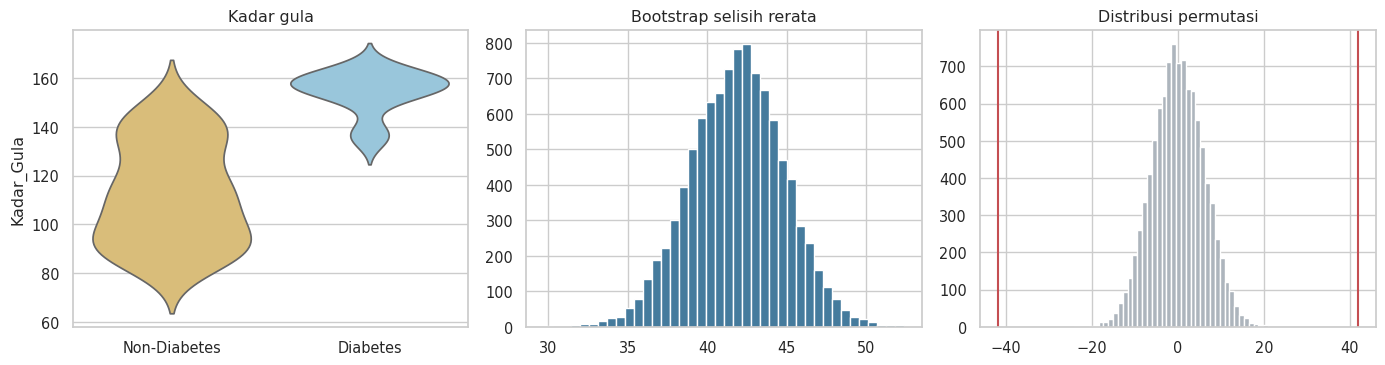

In [ ]:
# H2 (utama): Kadar gula Diabetes vs non-Diabetes
a = df.loc[df[TARGET]=='Diabetes', 'Kadar_Gula'].values; b = df.loc[df[TARGET]!='Diabetes', 'Kadar_Gula'].values
print('Asumsi -> Shapiro p (Diabetes, non):', round(stats.shapiro(a).pvalue, 4), round(stats.shapiro(b).pvalue, 4),
      '| Levene p =', f'{stats.levene(a, b).pvalue:.1e}', '=> pakai Welch + uji non-parametrik')
t = stats.ttest_ind(a, b, equal_var=False); mw = stats.mannwhitneyu(a, b)
diff = a.mean()-b.mean(); se = np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
dfw = se**4/((a.var(ddof=1)/len(a))**2/(len(a)-1)+(b.var(ddof=1)/len(b))**2/(len(b)-1)); tc = stats.t.ppf(.975, dfw)
sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2)); g_ = (diff/sp)*(1-3/(4*(len(a)+len(b))-9))
bs = np.array([RNG.choice(a, len(a)).mean()-RNG.choice(b, len(b)).mean() for _ in range(10000)])
allv = np.r_[a, b]; perm = []
for _ in range(10000):
    RNG.shuffle(allv); perm.append(allv[:len(a)].mean()-allv[len(a):].mean())
p_perm = (np.sum(np.abs(perm) >= abs(diff))+1)/(10000+1)
print(f'Rerata: Diabetes={a.mean():.1f} vs lainnya={b.mean():.1f} | selisih={diff:.1f}')
print(f'Welch t({dfw:.1f})={t.statistic:.2f}, p={t.pvalue:.2e} | 95% CI [{diff-tc*se:.1f}; {diff+tc*se:.1f}]')
print(f'Bootstrap 95% CI [{np.percentile(bs,2.5):.1f}; {np.percentile(bs,97.5):.1f}] | Mann-Whitney p={mw.pvalue:.2e} | Permutasi p={p_perm:.5f} (batas resolusi)')
print(f"Hedges g={g_:.2f} | Probabilitas superioritas={mw.statistic/(len(a)*len(b)):.3f}")

# Kontrol pembaur (Umur, BMI) lewat regresi OLS
X = np.c_[np.ones(len(df)), (df[TARGET]=='Diabetes').astype(int), df['Umur'], df['BMI']]; y = df['Kadar_Gula'].values
beta = np.linalg.lstsq(X, y, rcond=None)[0]; res = y-X@beta; cov = (res@res/(len(y)-4))*np.linalg.inv(X.T@X)
pv = 2*stats.t.sf(abs(beta/np.sqrt(np.diag(cov))), len(y)-4)
print(pd.DataFrame({'koef': beta.round(2), 'SE': np.sqrt(np.diag(cov)).round(2), 'p': pv}, index=['Intersep','Diabetes','Umur','BMI']))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.violinplot(x=np.where(df[TARGET]=='Diabetes', 'Diabetes', 'Non-Diabetes'), y=df['Kadar_Gula'], inner=None, ax=ax[0], palette=['#e9c46a','#8ecae6'])
ax[0].set_title('Kadar gula'); ax[1].hist(bs, bins=40, color='#457b9d'); ax[1].set_title('Bootstrap selisih rerata')
ax[2].hist(perm, bins=40, color='#adb5bd'); ax[2].axvline(diff, color='r'); ax[2].axvline(-diff, color='r'); ax[2].set_title('Distribusi permutasi')
plt.tight_layout(); plt.show()

In [ ]:
# H3, H4, H5: uji asosiasi kategorik
def cramer_v(ct):
    c2 = stats.chi2_contingency(ct, correction=False)[0]; return np.sqrt(c2/(ct.values.sum()*(min(ct.shape)-1)))
ct3 = pd.crosstab(df['Gaya_Hidup'], df[TARGET]); c2, p3, dof, exp = stats.chi2_contingency(ct3)
print(f'H3 Gaya_Hidup : chi2({dof})={c2:.1f}, p={p3:.2e}, V={cramer_v(ct3):.2f} | sel harapan <5: {(exp<5).mean()*100:.0f}% (asumsi dilanggar -> cek permutasi)')
y_perm = df[TARGET].values.copy(); obs = c2; cnt = 0
for _ in range(5000):
    RNG.shuffle(y_perm); cnt += stats.chi2_contingency(pd.crosstab(df['Gaya_Hidup'], y_perm), correction=False)[0] >= obs
print(f'   Uji permutasi p = {(cnt+1)/5001:.4f}')

sakit = np.where(df[TARGET]=='Normal', 'Normal', 'Sakit'); ct4 = pd.crosstab(df['Riwayat_Keluarga'], sakit)
print('\nH4 Riwayat_Keluarga vs Sakit'); display(ct4); print(f'   Fisher exact p = {stats.fisher_exact(ct4).pvalue:.2e} (sel kosong -> OR tidak boleh dibaca literal)')

ct5 = pd.crosstab(df['Jenis_Kelamin'], df[TARGET]); c5, p5, _, _ = stats.chi2_contingency(ct5)
print(f'\nH5 Jenis_Kelamin: chi2={c5:.2f}, p={p5:.3f}, V={cramer_v(ct5):.2f} -> gagal menolak H0 (kontrol negatif)')

H3 Gaya_Hidup : chi2(6)=108.1, p=5.14e-21, V=0.73 | sel harapan <5: 25% (asumsi dilanggar -> cek permutasi)
   Uji permutasi p = 0.0002

H4 Riwayat_Keluarga vs Sakit


col_0,Normal,Sakit
Riwayat_Keluarga,,
Tidak,30,2
Ya,0,69


   Fisher exact p = 1.19e-23 (sel kosong -> OR tidak boleh dibaca literal)

H5 Jenis_Kelamin: chi2=0.37, p=0.947, V=0.06 -> gagal menolak H0 (kontrol negatif)


In [ ]:
# Koreksi uji berganda (Holm) untuk 5 hipotesis
ps = {'H1 ANOVA': p, 'H2 Welch': t.pvalue, 'H3 Chi2': p3, 'H4 Fisher': stats.fisher_exact(ct4).pvalue, 'H5 Chi2': p5}
vals = np.array(list(ps.values())); o = np.argsort(vals); adj = np.empty(len(vals)); run = 0
for r, i in enumerate(o): run = max(run, (len(vals)-r)*vals[i]); adj[i] = min(1, run)
pd.DataFrame({'p_mentah': vals, 'p_Holm': adj, 'keputusan(a=0,05)': np.where(adj < .05, 'Tolak H0', 'Gagal tolak H0')}, index=ps.keys())

,p_mentah,p_Holm,"keputusan(a=0,05)"
H1 ANOVA,5.869001e-59,2.934501e-58,Tolak H0
H2 Welch,2.426480e-24,9.705918e-24,Tolak H0
H3 Chi2,5.135044e-21,1.027009e-20,Tolak H0
H4 Fisher,1.187080e-23,3.561241e-23,Tolak H0
H5 Chi2,9.469826e-01,9.469826e-01,Gagal tolak H0


## 7. Pemodelan Prediktif
Pipeline memakai **fitur mentah** (agar mudah dipakai di aplikasi Gradio): fitur numerik distandardisasi, `Jenis_Kelamin` dan `Riwayat_Keluarga` di-encode biner, `Gaya_Hidup` di-encode ordinal.
Validasi: *Stratified 5-fold CV berulang 5×*. Kontrol negatif (hanya `Jenis_Kelamin`) dipakai untuk memeriksa kebocoran.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split, cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

FEATURES = NUM + CAT
def make_pre(feats):
    num = [c for c in feats if c in NUM]; steps = []
    if num: steps.append(('num', StandardScaler(), num))
    if 'Jenis_Kelamin' in feats:    steps.append(('jk', OrdinalEncoder(categories=[['Perempuan','Laki-laki']]), ['Jenis_Kelamin']))
    if 'Riwayat_Keluarga' in feats: steps.append(('rk', OrdinalEncoder(categories=[['Tidak','Ya']]), ['Riwayat_Keluarga']))
    if 'Gaya_Hidup' in feats:       steps.append(('gh', OrdinalEncoder(categories=[['Sehat','Sedang','Tidak_Sehat']]), ['Gaya_Hidup']))
    return ColumnTransformer(steps)

MODELS = {
    'Regresi Logistik': LogisticRegression(max_iter=3000),
    'Random Forest':    RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
SKENARIO = {'Semua fitur': FEATURES,
            'Tanpa Riwayat & Gaya Hidup': NUM + ['Jenis_Kelamin'],
            'Kontrol negatif (hanya Jenis_Kelamin)': ['Jenis_Kelamin']}
X, y = df[FEATURES], df[TARGET]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
rows = []
for sk, fs in SKENARIO.items():
    for mn, m in MODELS.items():
        r = cross_validate(Pipeline([('pre', make_pre(fs)), ('clf', m)]), df[fs], y, cv=cv, scoring=['accuracy','f1_macro'])
        rows.append((sk, mn, r['test_accuracy'].mean(), r['test_accuracy'].std(), r['test_f1_macro'].mean()))
hasil = pd.DataFrame(rows, columns=['skenario','model','akurasi','sd_akurasi','f1_macro']).round(3)
print('Baseline kelas mayoritas =', round(y.value_counts(normalize=True).max(), 3)); hasil

Baseline kelas mayoritas = 0.297


,skenario,model,akurasi,sd_akurasi,f1_macro
0,Semua fitur,Regresi Logistik,0.980,0.024,0.980
1,Semua fitur,Random Forest,0.980,0.024,0.979
2,Semua fitur,Gradient Boosting,0.958,0.041,0.957
3,Tanpa Riwayat & Gaya Hidup,Regresi Logistik,0.990,0.020,0.989
4,Tanpa Riwayat & Gaya Hidup,Random Forest,0.980,0.024,0.979
5,Tanpa Riwayat & Gaya Hidup,Gradient Boosting,0.958,0.041,0.957
6,Kontrol negatif (hanya Jenis_Kelamin),Regresi Logistik,0.252,0.074,0.107
7,Kontrol negatif (hanya Jenis_Kelamin),Random Forest,0.232,0.078,0.106
8,Kontrol negatif (hanya Jenis_Kelamin),Gradient Boosting,0.252,0.074,0.107


Model terpilih: Regresi Logistik
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         6
    Diabetes       1.00      1.00      1.00         5
  Hipertensi       1.00      1.00      1.00         5
     Jantung       1.00      1.00      1.00         5

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



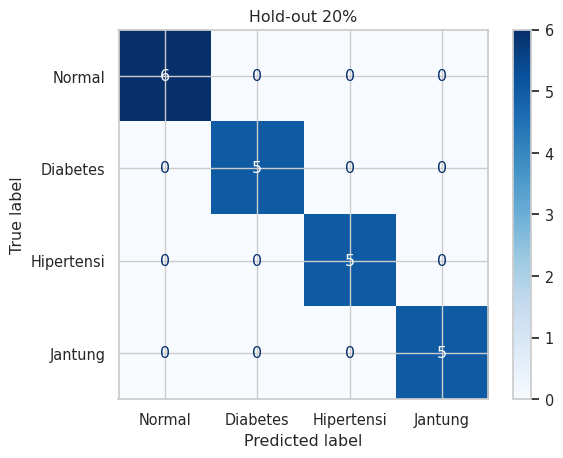

Pasien yang salah diklasifikasi (CV):


,Umur,Tekanan_Darah,Kadar_Gula,Detak_Jantung,BMI,Jenis_Kelamin,Riwayat_Keluarga,Gaya_Hidup,Penyakit,prediksi
89,46,149,122,83,28,Perempuan,Tidak,Sedang,Hipertensi,Normal
90,53,158,129,86,30,Laki-laki,Ya,Tidak_Sehat,Jantung,Hipertensi


In [ ]:
# Pilih model final dari skenario 'Semua fitur' (urutan MODELS dipakai sebagai pemutus seri: yang lebih sederhana didahulukan)
sub = hasil[hasil.skenario == 'Semua fitur'].reset_index(drop=True)
best_name = sub.loc[sub['f1_macro'].idxmax(), 'model']; print('Model terpilih:', best_name)

# Evaluasi hold-out 20% (sekadar ilustrasi; n kecil sehingga 1 pasien ~ 5% pada set uji)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
pipe_eval = Pipeline([('pre', make_pre(FEATURES)), ('clf', MODELS[best_name])]).fit(Xtr, ytr)
pred = pipe_eval.predict(Xte); print(classification_report(yte, pred, labels=ORD))
ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=ORD), display_labels=ORD).plot(cmap='Blues'); plt.title('Hold-out 20%'); plt.show()

# Prediksi validasi silang untuk seluruh data -> kesalahan klasifikasi
pr_cv = cross_val_predict(Pipeline([('pre', make_pre(FEATURES)), ('clf', MODELS[best_name])]), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42))
salah = df[pr_cv != y].assign(prediksi=pr_cv[pr_cv != y]); print('Pasien yang salah diklasifikasi (CV):'); display(salah)

In [ ]:
# Model final dilatih pada seluruh data lalu disimpan untuk aplikasi Gradio
import joblib
final = Pipeline([('pre', make_pre(FEATURES)), ('clf', MODELS[best_name])]).fit(X, y)
joblib.dump(final, os.path.join(BASE_DIR, 'model_penyakit.joblib'))

meta = {'model': best_name, 'classes': list(final.classes_), 'features': FEATURES,
        'ranges': {c: [float(df[c].min()), float(df[c].max())] for c in NUM},
        'cv_accuracy': float(sub.loc[sub.model == best_name, 'akurasi'].iloc[0]),
        'cv_f1_macro': float(sub.loc[sub.model == best_name, 'f1_macro'].iloc[0]), 'n_train': int(len(df))}
json.dump(meta, open(os.path.join(BASE_DIR, 'meta_model.json'), 'w'), indent=2)
print(json.dumps(meta, indent=2))

# Uji cepat: prediksi satu contoh
contoh = pd.DataFrame([{'Umur':45,'Tekanan_Darah':140,'Kadar_Gula':150,'Detak_Jantung':80,'BMI':28,'Jenis_Kelamin':'Perempuan','Riwayat_Keluarga':'Ya','Gaya_Hidup':'Tidak_Sehat'}])
print(dict(zip(final.classes_, final.predict_proba(contoh)[0].round(3))))

{
  "model": "Regresi Logistik",
  "classes": [
    "Diabetes",
    "Hipertensi",
    "Jantung",
    "Normal"
  ],
  "features": [
    "Umur",
    "Tekanan_Darah",
    "Kadar_Gula",
    "Detak_Jantung",
    "BMI",
    "Jenis_Kelamin",
    "Riwayat_Keluarga",
    "Gaya_Hidup"
  ],
  "ranges": {
    "Umur": [
      21.0,
      72.0
    ],
    "Tekanan_Darah": [
      116.0,
      185.0
    ],
    "Kadar_Gula": [
      81.0,
      165.0
    ],
    "Detak_Jantung": [
      69.0,
      99.0
    ],
    "BMI": [
      20.0,
      38.0
    ]
  },
  "cv_accuracy": 0.98,
  "cv_f1_macro": 0.98,
  "n_train": 101
}
{'Diabetes': np.float64(0.973), 'Hipertensi': np.float64(0.01), 'Jantung': np.float64(0.005), 'Normal': np.float64(0.011)}


## 8. Kesimpulan & Langkah Selanjutnya
- Data bersih secara formal (0 NaN, 0 duplikat, 0 pencilan IQR) tetapi **terlalu rapi secara statistik** → kemungkinan sintetis; validasi sumber data dahulu.
- H1–H4 signifikan dengan efek sangat besar dan tahan koreksi Holm; H5 (jenis kelamin) tidak signifikan, sesuai harapan sebagai kontrol negatif.
- Model mencapai akurasi tinggi, tetapi dengan n = 101 dan kelas yang hampir terpisah sempurna hal ini **bukan bukti kinerja klinis**.
- Langkah lanjut: data nyata lebih besar dan validasi eksternal; pemodelan multi-label untuk komorbid; audit fairness; klarifikasi satuan pengukuran.

**Aplikasi web:** jalankan sel-sel pada bagian 9 di bawah (Gradio).

## 9. Aplikasi Web Gradio
Sel di bawah membangun antarmuka web dari model yang **baru dilatih di notebook ini** (variabel `final`, `meta`, `df`) tanpa membaca berkas lain.
Jalankan sel-nya, lalu gunakan antarmuka yang muncul di bawah sel, atau buka **tautan publik** `https://xxxx.gradio.live` yang tampil di keluaran
(berlaku sementara, ±1 minggu, selama sesi Colab aktif). Tab: **Prediksi**, **Eksplorasi data**, **Tentang model**.

In [ ]:
import gradio as gr

PAL_G = PAL; RNG_G = meta['ranges']

def prediksi(umur, td, gula, hr, bmi, kelamin, riwayat, gaya):
    x = pd.DataFrame([{'Umur': umur, 'Tekanan_Darah': td, 'Kadar_Gula': gula, 'Detak_Jantung': hr, 'BMI': bmi,
                       'Jenis_Kelamin': kelamin, 'Riwayat_Keluarga': riwayat, 'Gaya_Hidup': gaya}])[meta['features']]
    proba = final.predict_proba(x)[0]
    skor = {c: float(p) for c, p in zip(final.classes_, proba)}
    top = max(skor, key=skor.get)
    catatan = []
    luar = [f'{k} = {v} (rentang data latih {RNG_G[k][0]:.0f}-{RNG_G[k][1]:.0f})'
            for k, v in zip(NUM, [umur, td, gula, hr, bmi]) if not RNG_G[k][0] <= v <= RNG_G[k][1]]
    if luar:
        catatan.append('⚠️ **Di luar rentang data latih** (model mengekstrapolasi, hasil kurang dapat dipercaya): ' + '; '.join(luar))
    if skor[top] < 0.6:
        catatan.append(f'⚠️ **Keyakinan rendah** ({skor[top]:.0%}). Kasus ini mirip pasien batas yang juga sulit bagi model.')
    if riwayat == 'Ya' and gaya == 'Sehat':
        catatan.append('ℹ️ Kombinasi *Riwayat keluarga = Ya* dan *Gaya hidup = Sehat* tidak ada pada data latih.')
    teks = f'### Prediksi: **{top}** ({skor[top]:.0%})\n\n' + '\n\n'.join(catatan)
    teks += '\n\n---\n*Alat demonstrasi akademik. Model dilatih pada 101 baris data yang tampak sintetis; bukan alat diagnosis dan bukan saran medis.*'
    return skor, teks

def plot_fitur(fitur):
    fig, ax = plt.subplots(figsize=(7, 4))
    if fitur in NUM:
        sns.boxplot(data=df, x=TARGET, y=fitur, order=ORD, hue=TARGET, palette=PAL_G, legend=False, ax=ax)
        sns.stripplot(data=df, x=TARGET, y=fitur, order=ORD, color='k', size=2.5, alpha=.5, ax=ax)
    else:
        pd.crosstab(df[fitur], df[TARGET])[ORD].plot(kind='bar', stacked=True, ax=ax, color=[PAL_G[k] for k in ORD], width=.7)
        ax.tick_params(axis='x', rotation=0); ax.set_xlabel('')
    ax.set_title(f'{fitur} menurut kelas penyakit'); plt.tight_layout(); plt.close(fig)
    return fig

def plot_korelasi():
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    sns.heatmap(df[NUM].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title('Korelasi Pearson'); plt.tight_layout(); plt.close(fig)
    return fig

TENTANG = f"""
### Tentang model
- **Model:** {meta['model']} (pipeline: standardisasi + encoding + klasifikasi 4 kelas)
- **Data latih:** {meta['n_train']} pasien, 8 fitur. Target: Normal, Diabetes, Hipertensi, Jantung
- **Validasi silang berulang (5-fold x 5):** akurasi ≈ {meta['cv_accuracy']:.0%}, F1-macro ≈ {meta['cv_f1_macro']:.2f}

### Keterbatasan
1. Data sangat kecil dan tampak **sintetis/terkurasi** (korelasi antar fitur ≈ 0,99). Akurasi tinggi mencerminkan masalah yang mudah, bukan kinerja klinis.
2. Setiap pasien hanya punya **satu label**, padahal komorbiditas umum terjadi.
3. Model tidak boleh dipakai **di luar rentang data latih**; aplikasi memberi peringatan bila input di luar rentang.
4. *Gaya hidup* dan *riwayat keluarga* hampir menentukan Normal vs Sakit; jika dicatat setelah diagnosis ada risiko kebocoran label.
5. **Bukan alat diagnosis dan bukan saran medis.**
"""

with gr.Blocks(title='Prediksi Penyakit - Demo EDA') as demo:
    gr.Markdown('# 🩺 Demo Klasifikasi Penyakit (Normal / Diabetes / Hipertensi / Jantung)\n*Alat demonstrasi, bukan alat medis.*')
    with gr.Tab('Prediksi'):
        with gr.Row():
            with gr.Column():
                umur = gr.Slider(15, 90, value=45, step=1, label='Umur (tahun)')
                td = gr.Slider(90, 220, value=140, step=1, label='Tekanan darah (mmHg)')
                gula = gr.Slider(60, 250, value=150, step=1, label='Kadar gula (mg/dL)')
                hr = gr.Slider(50, 130, value=80, step=1, label='Detak jantung (denyut/menit)')
                bmi = gr.Slider(15, 50, value=28, step=0.5, label='BMI (kg/m²)')
                kelamin = gr.Radio(['Laki-laki', 'Perempuan'], value='Perempuan', label='Jenis kelamin')
                riwayat = gr.Radio(['Ya', 'Tidak'], value='Ya', label='Riwayat keluarga')
                gaya = gr.Radio(['Sehat', 'Sedang', 'Tidak_Sehat'], value='Tidak_Sehat', label='Gaya hidup')
                tombol = gr.Button('Prediksi', variant='primary')
            with gr.Column():
                label = gr.Label(num_top_classes=4, label='Probabilitas tiap kelas')
                teks = gr.Markdown()
        inputs = [umur, td, gula, hr, bmi, kelamin, riwayat, gaya]
        tombol.click(prediksi, inputs, [label, teks])
        gr.Examples(examples=[[25, 120, 85, 72, 22, 'Laki-laki', 'Tidak', 'Sehat'],
                              [45, 140, 150, 80, 28, 'Perempuan', 'Ya', 'Tidak_Sehat'],
                              [60, 170, 110, 90, 32, 'Perempuan', 'Ya', 'Sedang'],
                              [65, 180, 130, 95, 34, 'Laki-laki', 'Ya', 'Tidak_Sehat'],
                              [46, 149, 122, 83, 28, 'Perempuan', 'Tidak', 'Sedang']],
                     inputs=inputs, label='Contoh pasien (dari data; yang terakhir adalah kasus batas)')
    with gr.Tab('Eksplorasi data'):
        pilih = gr.Dropdown(NUM + CAT, value='Kadar_Gula', label='Pilih fitur')
        grafik = gr.Plot(value=plot_fitur('Kadar_Gula'))
        pilih.change(plot_fitur, pilih, grafik)
        gr.Markdown('**Rerata fitur per kelas**')
        gr.Dataframe(value=df.groupby(TARGET)[NUM].mean().round(1).reindex(ORD).reset_index(), interactive=False)
        gr.Plot(value=plot_korelasi())
        with gr.Accordion('Pratinjau dataset', open=False):
            gr.Dataframe(value=df, interactive=False)
    with gr.Tab('Tentang model'):
        gr.Markdown(TENTANG)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a49e102b036205cdf2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
